In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
      f1_score,
 classification_report,
    confusion_matrix,
     ConfusionMatrixDisplay
)
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

In [5]:
# load the dataset

df = pd.read_csv("Adm.csv")
# display the first five rows
print(df.head())
# check the number of rows and columns
print("dataset shape:", df.shape)
print(df.info())

# check missing values
print(df.isnull().sum())
# check duplicate rows
print("duplicate rows:", df.duplicated().sum())

# check admission probability statistics
print(df["Chance of Admit"].describe())

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   
3           4        322          110                  3  3.5  2.5  8.67   
4           5        314          103                  2  2.0  3.0  8.21   

   Research  Chance of Admit Application_DateTime  \
0         1             0.92  2022-01-01 09:00:00   
1         1             0.76  2022-01-02 09:00:00   
2         1             0.72  2022-01-04 09:00:00   
3         1             0.80  2022-01-06 09:00:00   
4         0             0.65  2022-01-08 09:00:00   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  
3   

admission_status
1    594
0    406
Name: count, dtype: int64


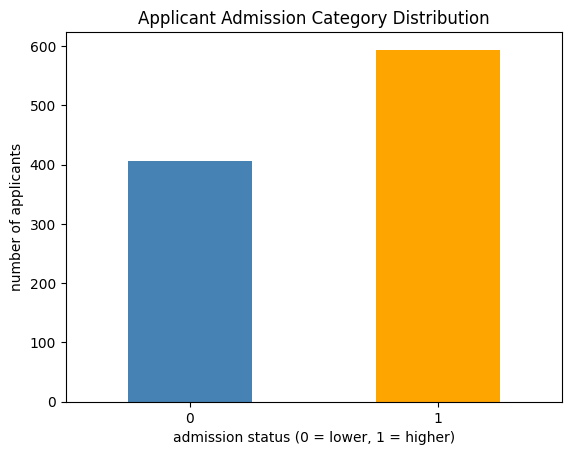

In [6]:
# remove duplicate rows
df = df.drop_duplicates().copy()
# remove rows without the target value
df = df.dropna(subset=["Chance of Admit"])
# create the classification target
df["admission_status"] = (
    df["Chance of Admit"] >= 0.70
).astype(int)

# check the number of applicants in each class
print(df["admission_status"].value_counts())
# display the class distribution
df["admission_status"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "orange"]
)
plt.title("Applicant Admission Category Distribution")
plt.xlabel("admission status (0 = lower, 1 = higher)")
plt.ylabel("number of applicants")
plt.xticks(rotation=0)
plt.show()

In [7]:
# select the input features
features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research",
    "region"
]

# convert the region into numeric columns
x = pd.get_dummies(
    df[features],
    columns=["region"],
    drop_first=True,
    dtype=int
)

# select the target
y = df["admission_status"]

# split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("training rows:", x_train.shape[0])
print("testing rows:", x_test.shape[0])
print("input features:", x.shape[1])

training rows: 800
testing rows: 200
input features: 12


In [8]:
# create the initial decision tree
tree_model = DecisionTreeClassifier(random_state=42)

# train the model
tree_model.fit(x_train, y_train)

# make predictions
train_pred = tree_model.predict(x_train)
test_pred = tree_model.predict(x_test)

# evaluate the initial model
print("training accuracy:", accuracy_score(y_train, train_pred))
print("testing accuracy:", accuracy_score(y_test, test_pred))
print("tree depth:", tree_model.get_depth())
print("number of leaves:", tree_model.get_n_leaves())

training accuracy: 1.0
testing accuracy: 0.575
tree depth: 16
number of leaves: 192


In [9]:
# define the values to test
params = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "class_weight": [None, "balanced"]
}

# search for the best combination
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# fit only on the training data
grid.fit(x_train, y_train)

# keep the best pre-pruned model
pre_pruned_model = grid.best_estimator_

print("best parameters:", grid.best_params_)
print("best cross-validation f1:", grid.best_score_)
print("pre-pruned tree depth:", pre_pruned_model.get_depth())
print("pre-pruned leaves:", pre_pruned_model.get_n_leaves())

best parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2}
best cross-validation f1: 0.7211780308440999
pre-pruned tree depth: 2
pre-pruned leaves: 4


In [12]:
# create a tree to calculate pruning values
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(x_train, y_train)

# calculate the cost-complexity pruning path
path = full_tree.cost_complexity_pruning_path(
    x_train,
    y_train
)

# get the alpha values
alphas = path.ccp_alphas
# remove the final alpha because it can produce a single-node tree
alphas = alphas[:-1]

# remove duplicate alpha values
alphas = sorted(set(alphas))

print("number of pruning values:", len(alphas))
print("first alpha values:", alphas[:10])

number of pruning values: 74
first alpha values: [np.float64(0.0), np.float64(0.0007638888888888889), np.float64(0.0009375), np.float64(0.0009789473684210525), np.float64(0.00099702380952381), np.float64(0.0009999999999999998), np.float64(0.0010416666666666667), np.float64(0.0010714285714285717), np.float64(0.0011111111111111111), np.float64(0.0011363636363636365)]


In [13]:
# create a list to store the results
pruning_results = []

# test each pruning value
for alpha in alphas:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    # evaluate using five-fold cross-validation
    from sklearn.model_selection import cross_val_score

    scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    pruning_results.append({
        "ccp_alpha": alpha,
        "mean_f1": scores.mean()
    })

# convert results into a dataframe
pruning_df = pd.DataFrame(pruning_results)

# display the best pruning values
print(
    pruning_df.sort_values(
        "mean_f1",
        ascending=False
    ).head(10)
)

# select the alpha with the best mean cross-validation f1
best_alpha = pruning_df.loc[
    pruning_df["mean_f1"].idxmax(),
    "ccp_alpha"
]

print("best pruning alpha:", best_alpha)

# train the post-pruned tree
post_pruned_model = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)
post_pruned_model.fit(x_train, y_train)

print("post-pruned depth:", post_pruned_model.get_depth())
print("post-pruned leaves:", post_pruned_model.get_n_leaves())

    ccp_alpha   mean_f1
72   0.010131  0.722328
69   0.005279  0.721613
67   0.004978  0.721265
68   0.005102  0.720537
70   0.006951  0.720163
71   0.007218  0.717604
65   0.004541  0.699037
66   0.004642  0.698168
55   0.002750  0.689834
62   0.003585  0.689310
best pruning alpha: 0.010131493506493533
post-pruned depth: 2
post-pruned leaves: 3


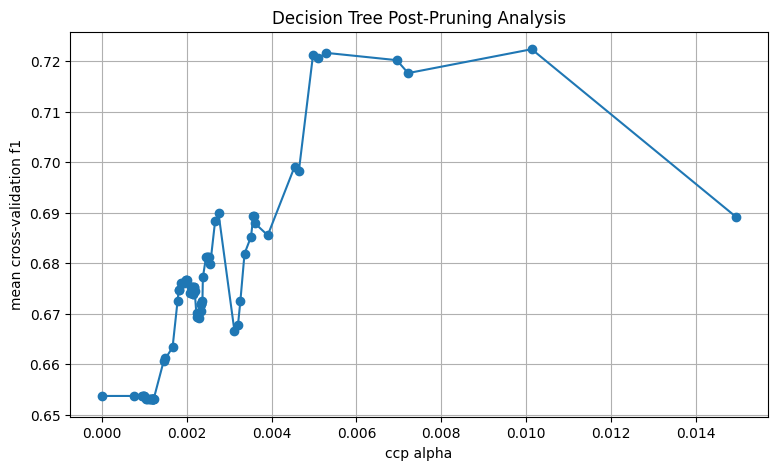

In [14]:
# plot alpha against cross-validation f1
plt.figure(figsize=(9, 5))

plt.plot(
    pruning_df["ccp_alpha"],
    pruning_df["mean_f1"],
    marker="o"
)

plt.xlabel("ccp alpha")
plt.ylabel("mean cross-validation f1")
plt.title("Decision Tree Post-Pruning Analysis")
plt.grid(True)
plt.show()

In [15]:
# store the models for comparison
models = {
    "initial tree": tree_model,
    "pre-pruned tree": pre_pruned_model,
    "post-pruned tree": post_pruned_model
}

# store the evaluation results
results = []

# evaluate each model
for name, model in models.items():
    train_prediction = model.predict(x_train)
    test_prediction = model.predict(x_test)

    results.append({
        "model": name,
        "train_accuracy": accuracy_score(
            y_train, train_prediction
        ),
        "test_accuracy": accuracy_score(
            y_test, test_prediction
        ),
        "precision": precision_score(
            y_test, test_prediction, zero_division=0
        ),
        "recall": recall_score(
            y_test, test_prediction, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, test_prediction, zero_division=0
        ),
        "depth": model.get_depth(),
        "leaves": model.get_n_leaves()
    })

# display the comparison table
results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))

           model  train_accuracy  test_accuracy  precision  recall  f1_score  depth  leaves
    initial tree           1.000          0.575      0.649   0.622     0.635     16     192
 pre-pruned tree           0.679          0.635      0.705   0.664     0.684      2       4
post-pruned tree           0.679          0.635      0.705   0.664     0.684      2       3


               precision    recall  f1-score   support

 lower chance       0.55      0.59      0.57        81
higher chance       0.71      0.66      0.68       119

     accuracy                           0.64       200
    macro avg       0.63      0.63      0.63       200
 weighted avg       0.64      0.64      0.64       200



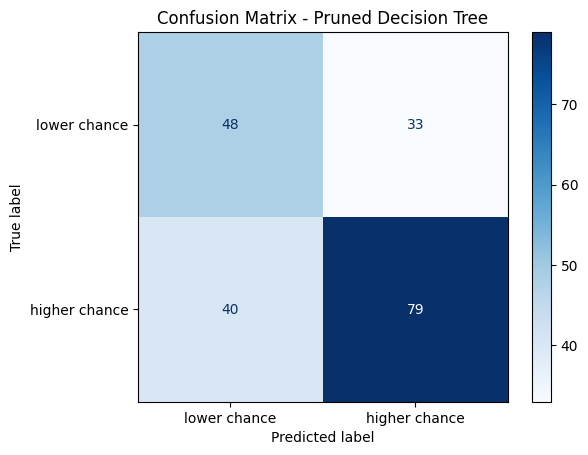

In [16]:
# make predictions with the final model
final_pred = post_pruned_model.predict(x_test)

# display the classification report
print(
    classification_report(
        y_test,
        final_pred,
        target_names=["lower chance", "higher chance"],
        zero_division=0
    )
)

# display the confusion matrix
cm = confusion_matrix(y_test, final_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["lower chance", "higher chance"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Pruned Decision Tree")
plt.show()

          feature  importance      std
             CGPA    0.070644 0.020094
        GRE Score    0.057236 0.022697
      TOEFL Score    0.000000 0.000000
University Rating    0.000000 0.000000
              SOP    0.000000 0.000000
              LOR    0.000000 0.000000
         Research    0.000000 0.000000
      region_East    0.000000 0.000000
     region_North    0.000000 0.000000
 region_Northeast    0.000000 0.000000
     region_South    0.000000 0.000000
      region_West    0.000000 0.000000


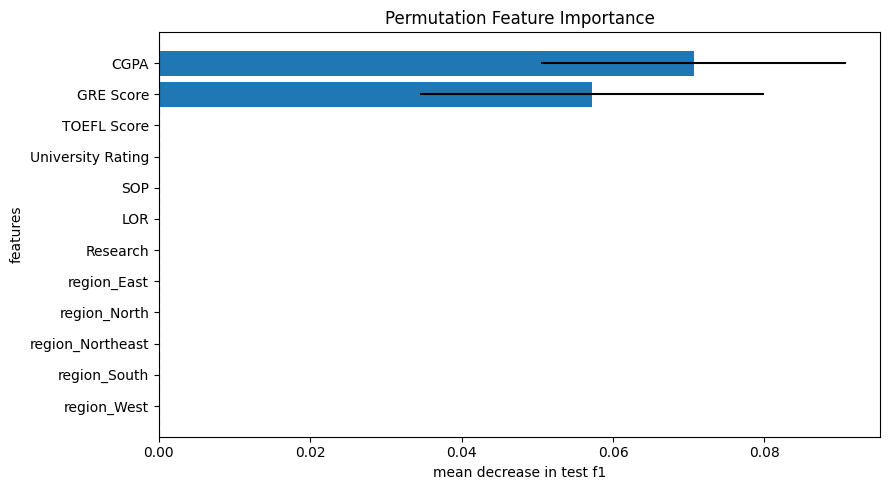

In [17]:
# calculate permutation importance on the test data
perm = permutation_importance(
    post_pruned_model,
    x_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# create a dataframe
perm_df = pd.DataFrame({
    "feature": x_test.columns,
    "importance": perm.importances_mean,
    "std": perm.importances_std
})

# sort the results
perm_df = perm_df.sort_values(
    "importance",
    ascending=False
)

print(perm_df.to_string(index=False))

# plot permutation importance
plt.figure(figsize=(9, 5))

plt.barh(
    perm_df["feature"],
    perm_df["importance"],
    xerr=perm_df["std"]
)

plt.xlabel("mean decrease in test f1")
plt.ylabel("features")
plt.title("Permutation Feature Importance")
plt.axvline(0, linestyle="--")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

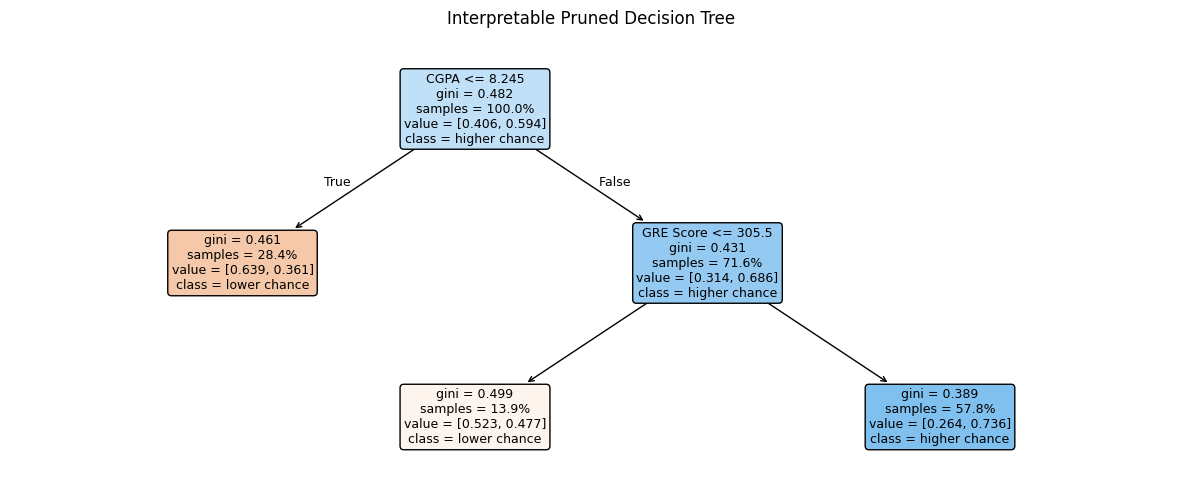

In [20]:
# display the pruned decision tree
plt.figure(figsize=(15, 6))

plot_tree(
    post_pruned_model,
    feature_names=list(x_train.columns),
    class_names=["lower chance", "higher chance"],
    filled=True,
    rounded=True,
    fontsize=9,
    proportion=True
)

plt.title("Interpretable Pruned Decision Tree")
plt.show()

In [21]:
# import the rule export function
from sklearn.tree import export_text

# convert the tree into readable rules
rules = export_text(
    post_pruned_model,
    feature_names=list(x_train.columns)
)

# display the rules
print(rules)

|--- CGPA <= 8.24
|   |--- class: 0
|--- CGPA >  8.24
|   |--- GRE Score <= 305.50
|   |   |--- class: 0
|   |--- GRE Score >  305.50
|   |   |--- class: 1

